In [222]:
import pandas as pd
import re
import networkx as nx

import matplotlib.pyplot as plt

## Read data

In [164]:
influ = pd.read_csv(r"C:\Users\marle\Files\programowanie\Influencer_Selection\data\influencer_info.csv")

In [165]:
influ.isna().sum()

Unnamed: 0          0
influencer          0
keyword             0
ad_name             0
subscribers         0
num_videos          0
view                0
clear_subscriber    0
clear_video         0
clear_view          0
average_view        0
negative            0
positive            0
dtype: int64

In [166]:
influ.duplicated(subset='influencer').sum()

0

In [167]:
79082010/804000

98.36070895522388

In [168]:
influ

,Unnamed: 0,influencer,keyword,ad_name,subscribers,num_videos,view,clear_subscriber,clear_video,clear_view,average_view,negative,positive
0,0,areumsongee아름송이,뷰티 & 메이크업 & 패션 & 뷰티,"['나의 결혼계획 발표...타투소개 , 30대의 노화관리(?) 그리고 스무살 송충이...",구독자 80.4만명,266,"조회수 79,082,010회",804000,266,79082010,98.360709,0.165041,0.834959
1,1,솔업 sollup,패션 & 뷰티 & 코디 & 룩북,['아트가 라이프에 주는 가치에 대해? 아트 컬렉팅을 시작하는 쉬운 방법 공유해요!...,구독자 5.67만명,126,"조회수 3,560,810회",56700,126,3560810,62.800882,0.126663,0.873337
2,2,에익쿠,만화 & 애니메이션 & 언어,"['ENG) 첫 임무 / MBTI 저승사자 만화 ep.3', 'MBTI 올리브영 할...",구독자 33.1만명,176,"조회수 77,560,785회",331000,176,77560785,234.322613,0.264321,0.735679
3,3,마빡,게임 & 음식,['경북 성주로 밀웜사육하는곳가서 직접먹방!! [ Mealworm Mukbang ]...,구독자 14.6만명,2.2천,"조회수 47,977,810회",146000,2200,47977810,328.615137,0.434274,0.565726
4,4,nbkorea,패션 & 뷰티 & 스포츠 의류,['[뉴발란스] New Balance Womens Sports Club with 뉴...,구독자 6.95천명,481,"조회수 16,441,242회",6950,481,16441242,2365.646331,0.032029,0.967971
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3807,3807,핵꿀잼,"영화 & 교육 & 직업, 언어","['드라마 아니고 영환줄..', '미친 삼각 말아주는 #최악의악', '유재석이 기다...",구독자 16.6만명,1.3천,"조회수 878,905,265회",166000,1300,878905265,5294.610030,0.811188,0.188812
3808,3808,지식인사이드,"의료 & 건강, 신체 질환 & 컨디션 이상 & 재테크","[""EBS 명의 출연 정형외과 전문의, 제 부모님이 무릎 아프다고 하시면 딱 '이것...",구독자 117만명,410,"조회수 194,240,972회",117000,410,194240972,1660.179248,0.316265,0.683735
3809,3809,흥삶이네 Heungsam's Life,식품 & 먹방 & 레시피,"['부모님 모시고 홍천 한우 먹고왔습니다.', '부모님 모시고 군산에 다녀왔습니다....",구독자 6.49만명,27,"조회수 7,276,901회",64900,27,7276901,112.124823,0.270422,0.729578
3810,3810,리뷰하는고래,"IT & 전자기기, 소비자 가전 & 취미 & 공예, 특별한 날","['""왜 안춥지?"" 난방비 절약하는 겨울 꿀템 추천 제품 5가지', '갤럭시도 맥세...",구독자 1.43만명,93,"조회수 18,304,358회",14300,93,18304358,1280.025035,0.520805,0.479195


In [169]:
adv = pd.read_csv(r"C:\Users\marle\Files\programowanie\Influencer_Selection\data\advertiser_influencer_link.csv")

In [170]:
adv.isna().sum()

Unnamed: 0    0
title         0
advertiser    0
influencer    0
date          0
view          0
keyword       0
videoID       0
dtype: int64

In [171]:
adv

,Unnamed: 0,title,advertiser,influencer,date,view,keyword,videoID
0,0,현 올영알바가 추천하는 향수대신 쓰기 좋은 갓성비 향기템 추천 #올리브영알바 #올영...,더블유드레스룸,유나러부,23.08.26,조회수 3K,뷰티 & 메이크업,VW5HM-wVV08
1,1,"3배 더 예뻐지는 ""컨투어링"" 멱살 잡고 알려드림✊? | 죽어가는 이목구비 소생법 ...",페리페라,지냐 Jinyaa,23.08.26,조회수 73K,뷰티 & 메이크업,wCjzu3OT2XE
2,2,갸루 언니✌ to K-아이돌?언니 데뷔해줘요,에뛰드,회사원A,23.08.26,조회수 32K,뷰티 & 메이크업,T8PLbhE6fqc
3,3,토너 200% 활용법 #토너팩하는법 #더마펌,더마펌,랏뚜 Beauty,23.08.26,조회수 51,뷰티 & 메이크업,olFCmnJ-znY
4,4,베네피트 신상틴트? 태연PICK 6컬러 발라보기! (스플래시 듀이틴트&플러시 벨벳틴...,베네피트,HANE 하네,23.08.26,조회수 3K,뷰티 & 메이크업,_y9BEWs3obc
...,...,...,...,...,...,...,...,...
25169,25169,이런거까지 된다는 요즘 로봇청소기 ㄷㄷ,아이리버,공간일기,23.08.28,조회수 8천,IT & 전자기기,dDwK_uvlqh0
25170,25170,미리보는 남자 가을코디 (with 갤럭시 Z 플립5),삼성전자,코디메이커 피로,23.08.27,조회수 4만,IT & 전자기기,6ugZ1JO600o
25171,25171,"ENG) 다이노탱 때문에 백화점 오픈런이라는걸 해봄😱 귀여운 마그넷 만들고, 콩알이...",삼성전자,코지데이 CozyDay,23.08.27,조회수 2만,IT & 전자기기,HHUiqWBWcoA
25172,25172,손 그림 VS 액정 타블렛 ? 뉴진스 하니,엑스피펜,MerryMa 메리마,23.08.26,조회수 1백만,IT & 전자기기,-0JNe3se7JM


## Clean columns

In [172]:
adv['view'] = adv['view'].str.replace('조회수', '').str.strip()

In [173]:
adv['symbol'] = adv['view'].str.replace(r'[0-9.,\s]', '', regex=True)

In [174]:
adv['view'].str.replace(r'[0-9.,\s]', '', regex=True).value_counts()

view
K     22707
M      1096
        944
만       313
천        95
백만       19
Name: count, dtype: int64

In [175]:
def parse_views(value):
    if 'K'in value or '천' in value:
        multiplier = 1000
    elif 'M' in value or '백만' in value:
        multiplier = 1000000
    elif '만' in value:
        multiplier = 10000
    else:
        multiplier = 1
    return int(float(re.sub(r'[^0-9.,\s]', '', value)) * multiplier)

In [176]:
test_values = ['3K', '4만', '1.5M', '2백만', '250', '3.5천']

for value in test_values:
    print(value, parse_views(value))

3K 3000
4만 40000
1.5M 1500000
2백만 2000000
250 250
3.5천 3500


In [177]:
adv = adv.assign(
    views_numeric = adv['view'].apply(parse_views)
)

In [178]:
adv['date'] = pd.to_datetime(adv['date'], format='%y.%m.%d')
adv['month'] = adv['date'].dt.month

In [179]:
adv.groupby(['advertiser', 'influencer']).size().reset_index().sort_values(0, ascending=False)

,advertiser,influencer,0
4337,리니지M,렌,623
4339,리니지M,무티,567
4347,리니지M,카라,343
4336,리니지M,도건,336
4354,리니지W,똘끼100%,274
...,...,...,...
5411,미쟝센,아르몽Ahrumongg,1
5412,미쟝센,안녕하세미,1
5413,미쟝센,엔조이커플enjoycouple,1
5414,미쟝센,이응oioio,1


In [180]:
final_df = adv.groupby(['advertiser', 'influencer']).agg(
    n_videos=('videoID','nunique'),
    median_views=('views_numeric','median'),
    min_views=('views_numeric','min'),
    max_views=('views_numeric','max'),
    active_months=('month', 'nunique')
).reset_index()

In [181]:
final_df 

,advertiser,influencer,n_videos,median_views,min_views,max_views,active_months
0,러쉬로얄,겜브링 GGAM BRING,1,57000.0,57000,57000,1
1,러쉬로얄,깨박이,1,14000.0,14000,14000,1
2,러쉬로얄,킴성태TV,1,63000.0,63000,63000,1
3,1664 블랑,피치림 Peach Rim,1,304000.0,304000,304000,1
4,1943,K-현실고증,1,250000.0,250000,250000,1
...,...,...,...,...,...,...,...
14902,힘난다,고기남자 MeatMan,1,2700000.0,2700000,2700000,1
14903,힘난다,둥이키친 DUNGYIKITCHEN,1,9000.0,9000,9000,1
14904,힘난다,요리용디 Yori Yongd,5,870000.0,519000,1300000,4
14905,힘펠,가봄TV / gabomTV,1,6000.0,6000,6000,1


In [182]:
final_df[['n_videos', 'active_months']].describe()

,n_videos,active_months
count,14907.000000,14907.000000
mean,1.686188,1.235929
std,10.214787,0.762623
min,1.000000,1.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,1.000000,1.000000
max,623.000000,12.000000


In [183]:
final_df['active_months'].value_counts().sort_index()

active_months
1     12752
2      1498
3       361
4       124
5        77
6        31
7        24
8        17
9        12
10        8
11        2
12        1
Name: count, dtype: int64

In [184]:
final_df.loc[
    final_df['n_videos'] >= 4,
    'active_months'
].value_counts().sort_index()

active_months
1      34
2      43
3      88
4     124
5      77
6      31
7      24
8      17
9      12
10      8
11      2
12      1
Name: count, dtype: int64

<Axes: xlabel='n_videos', ylabel='Count'>

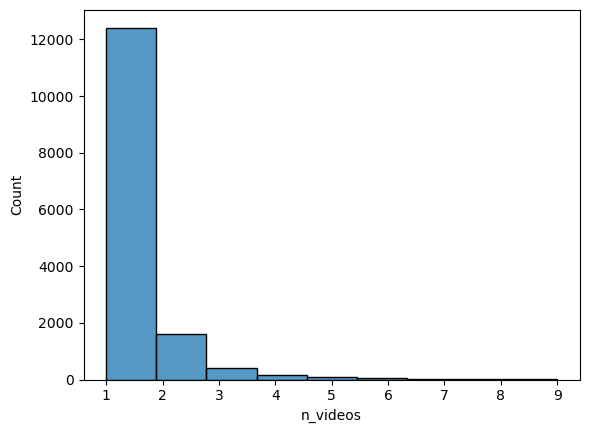

In [185]:
import seaborn as sns

sns.histplot(final_df[final_df['n_videos'] < 10], x='n_videos', bins=9)

## build graph

In [186]:
G = nx.Graph()

In [187]:
print(G.number_of_nodes())  # 0
print(G.number_of_edges())  # 0

0
0


### nodes

In [188]:
brands = final_df['advertiser'].unique()

G.add_nodes_from(
    [('brand', brand) for brand in brands],
    bipartite=0
)

In [189]:
influencers = final_df['influencer'].unique()

G.add_nodes_from(
    [('influencer', influencer) for influencer in influencers],
    bipartite=1
)

### edges

In [190]:
for row in final_df.itertuples(index=False):
    G.add_edge(
        ('brand', row.advertiser),
        ('influencer', row.influencer),
        n_videos=row.n_videos,
        median_views=row.median_views,
        min_views=row.min_views,
        max_views=row.max_views,
        active_months= row.active_months
    )

In [191]:
print(G.number_of_nodes())
print(G.number_of_edges())

5698
14907


In [192]:
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

degrees = dict(G.degree())

print("Avg degree:", sum(degrees.values()) / len(degrees))
print("Max degree:", max(degrees.values()))

Nodes: 5698
Edges: 14907
Avg degree: 5.232362232362233
Max degree: 245


### add influ attributes

In [193]:
for row in influ.itertuples(index=False):
    node = ('influencer', row.influencer)
    G.nodes[node]['followers'] = row.clear_subscriber
    G.nodes[node]['views'] = row.clear_view
    G.nodes[node]['added_videos'] = row.clear_video

### add edge weight

In [194]:
for u, v, attrs in G.edges(data=True):
    attrs['weight'] = 0.8 * attrs['median_views'] if attrs['n_videos'] < 4 else attrs['median_views']

## graph EDA

In [197]:
degrees = dict(G.degree())

In [198]:
influencer_degrees = {
    node: degree
    for node, degree in degrees.items()
    if node[0] == 'influencer'
}

brand_degrees = {
    node: degree
    for node, degree in degrees.items()
    if node[0] == 'brand'
}

In [201]:
influencer_stats = pd.Series(influencer_degrees).describe()
brand_stats = pd.Series(brand_degrees).describe()

print("INFLUENCERZY")
print(influencer_stats)

print("\nMARKI")
print(brand_stats)

INFLUENCERZY
count    3812.000000
mean        3.910546
std         5.681397
min         1.000000
25%         1.000000
50%         2.000000
75%         4.000000
max        56.000000
dtype: float64

MARKI
count    1886.00000
mean        7.90403
std        16.09474
min         1.00000
25%         1.00000
50%         3.00000
75%         7.00000
max       245.00000
dtype: float64


In [220]:
influencer_graph_df = pd.DataFrame([
    {'influencer': node[1],
     'degree': G.degree(node),
     'followers': G.nodes[node]['followers']
     }
     for node in G.nodes() if G.nodes[node]['bipartite'] == 1
])

## There is a weak positive correlation between the number of brand partnerships and the number of followers

In [221]:
influencer_graph_df[['degree', 'followers']].corr(method='spearman')

,degree,followers
degree,1.000000,0.190405
followers,0.190405,1.000000


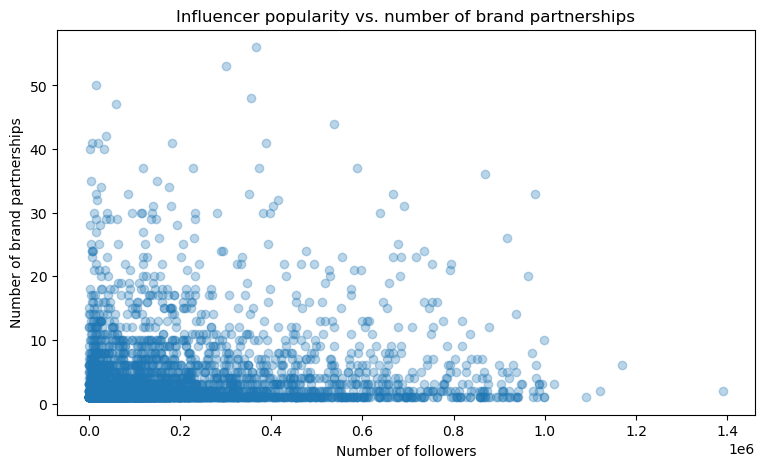

In [226]:
plt.figure(figsize=(9, 5))

plt.scatter(
    influencer_graph_df['followers'],
    influencer_graph_df['degree'],
    alpha=0.3
)

plt.xlabel('Number of followers')
plt.ylabel('Number of brand partnerships')
plt.title('Influencer popularity vs. number of brand partnerships')
plt.show()

## Select brands with the highest number of partnerships

In [231]:
top_brands = sorted(
    brand_degrees,
    key=brand_degrees.get,
    reverse=True
)[:2]

print(top_brands)

[('brand', '삼성전자'), ('brand', 'LG전자')]


### Influencers they share

In [233]:
common = list(nx.common_neighbors(G, top_brands[0], top_brands[1]))

print("Number of shared influencers:", len(common))

Number of shared influencers: 55


In [238]:
samsung_influ = set(G.neighbors(top_brands[0]))
lg_influ = set(G.neighbors(top_brands[1]))

In [239]:
intersection = len(samsung_influ & lg_influ)
union = len(samsung_influ | lg_influ)

jaccard = intersection / union

print("Samsung influencers:", len(samsung_influ))
print("LG influencers:", len(lg_influ))
print("Shared influencers:", intersection)
print("Union:", union)
print("Jaccard similarity:", round(jaccard, 3))

Samsung influencers: 245
LG influencers: 232
Shared influencers: 55
Union: 422
Jaccard similarity: 0.13


## Have these 55 influencers partnered witm other brands?

In [246]:
shared_degrees = pd.Series(
    [G.degree(node) for node in samsung_influ & lg_influ]
)

shared_degrees.describe()

count    55.000000
mean     11.781818
std       7.934199
min       2.000000
25%       6.000000
50%      10.000000
75%      16.000000
max      35.000000
dtype: float64